# Infrastructure sanity
## Load multi-omics table (no transformation)

Purpose:
- Load the preprocessed TCGA-BRCA multi-omics dataset
- Identify patient identifiers and feature columns
- Perform no reshaping, normalization, or filtering

At this stage:
- The dataframe is treated as immutable input
- No modeling assumptions are introduced


In [1]:
import pandas as pd

DATA_DIR = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics"
omics_path = f"{DATA_DIR}/multiomics.csv" 
df = pd.read_csv(omics_path)

print(df.shape)
df.head()

(950, 52006)


,Unnamed: 0,A1BG_RNA,A1CF_RNA,A2M_RNA,A2ML1_RNA,A4GALT_RNA,AAAS_RNA,AACS_RNA,AADAC_RNA,AADACL2_RNA,...,ZW10_METH,ZWILCH_METH,ZWINT_METH,ZXDA_METH,ZXDB_METH,ZXDC_METH,ZYG11B_METH,ZZEF1_METH,ZZZ3_METH,PAM50_subtype
0,TCGA-3C-AAAU-01A,0.603430,0.006980,173.677944,0.243545,4.710933,32.657576,14.401695,0.000000,0.000000,...,0.049608,0.109047,0.057910,0.321347,0.246885,0.087415,0.279483,0.084813,0.062644,LumB
1,TCGA-3C-AALI-01A,0.682114,0.104153,193.408085,0.241419,8.664761,38.951727,9.541005,0.111429,0.000000,...,0.052631,0.105452,0.053972,0.544478,0.374416,0.126821,0.309291,0.071378,0.059151,Her2
2,TCGA-3C-AALJ-01A,0.450187,0.057684,204.877310,0.096761,28.290763,28.007448,15.861093,0.084856,0.000000,...,0.052762,0.133061,0.050686,0.281517,0.306637,0.139180,0.279394,0.069621,0.059139,LumB
3,TCGA-3C-AALK-01A,0.276973,0.020354,261.945450,0.081943,25.766596,30.502503,9.115599,0.399227,0.025697,...,0.050637,0.151608,0.054225,0.463866,0.341055,0.144383,0.273561,0.065023,0.060002,Normal
4,TCGA-4H-AAAK-01A,0.564652,0.008709,290.776611,0.222050,21.368544,41.240604,11.252331,0.051245,0.032984,...,0.056702,0.103626,0.053409,0.500414,0.307140,0.134141,0.268453,0.080721,0.062508,Normal


In [2]:
# Inspect columns
print(df.columns[:10])
print(df.columns[-10:])

Index(['Unnamed: 0', 'A1BG_RNA', 'A1CF_RNA', 'A2M_RNA', 'A2ML1_RNA',
       'A4GALT_RNA', 'AAAS_RNA', 'AACS_RNA', 'AADAC_RNA', 'AADACL2_RNA'],
      dtype='object')
Index(['ZW10_METH', 'ZWILCH_METH', 'ZWINT_METH', 'ZXDA_METH', 'ZXDB_METH',
       'ZXDC_METH', 'ZYG11B_METH', 'ZZEF1_METH', 'ZZZ3_METH', 'PAM50_subtype'],
      dtype='object')


## Explicit patient identifier

The uploaded CSV contains patient identifiers in an unnamed column.
For clarity, reproducibility, and safe merging with clinical data,
this column is explicitly renamed to `patient_id`.

At this stage:
- No rows are dropped
- No reindexing is performed
- The column is kept as a regular dataframe column (not index)


In [3]:
# Rename patient ID column explicitly
assert "Unnamed: 0" in df.columns, "Expected unnamed patient ID column not found"

df = df.rename(columns={"Unnamed: 0": "patient_id"})

# Basic sanity checks
print("Columns after renaming:")
print(df.columns[:5])

print("\nExample patient IDs:")
print(df["patient_id"].head())

# Check uniqueness
n_unique = df["patient_id"].nunique()
n_rows = len(df)

print(f"\nUnique patient IDs: {n_unique}")
print(f"Total rows: {n_rows}")

assert n_unique == n_rows, "Patient IDs are not unique"


Columns after renaming:
Index(['patient_id', 'A1BG_RNA', 'A1CF_RNA', 'A2M_RNA', 'A2ML1_RNA'], dtype='object')

Example patient IDs:
0    TCGA-3C-AAAU-01A
1    TCGA-3C-AALI-01A
2    TCGA-3C-AALJ-01A
3    TCGA-3C-AALK-01A
4    TCGA-4H-AAAK-01A
Name: patient_id, dtype: object

Unique patient IDs: 950
Total rows: 950


## Feature parsing and modality separation

We separate patient identifiers, metadata, and molecular features.
Molecular features are parsed by modality suffix:

- `_RNA`  → RNA expression
- `_CNV`  → Copy number variation
- `_METH` → DNA methylation
- `_SNV`  → Somatic mutations

No filtering, scaling, or transformation is applied at this stage.
This step only establishes structure.


In [4]:
# Identify metadata columns
ID_COL = "patient_id"
META_COLS = ["PAM50_subtype"]  # metadata only, never used for training

# All other columns are candidate molecular features
feature_cols = [c for c in df.columns if c not in [ID_COL] + META_COLS]

# Parse by modality suffix
modalities = {
    "RNA":  [c for c in feature_cols if c.endswith("_RNA")],
    "CNV":  [c for c in feature_cols if c.endswith("_CNV")],
    "METH": [c for c in feature_cols if c.endswith("_METH")],
    "SNV":  [c for c in feature_cols if c.endswith("_SNV")],
}

# Sanity checks
print("Feature counts by modality:")
for m, cols in modalities.items():
    print(f"{m}: {len(cols)}")

# Check for unassigned columns
assigned = set(sum(modalities.values(), []))
unassigned = set(feature_cols) - assigned

print(f"\nUnassigned feature columns: {len(unassigned)}")
if len(unassigned) > 0:
    print(list(unassigned)[:10])


Feature counts by modality:
RNA: 13001
CNV: 13001
METH: 13001
SNV: 13001

Unassigned feature columns: 0


## Dataset Loader

This class constructs a unified tensor representation:

$X ∈ ℝ^{(patients × genes × modalities)}$

- patients are aligned by TCGA barcode
- genes are aligned across all modalities
- modality order is fixed: [RNA, CNV, METH, SNV]

No preprocessing or scaling is applied here.


In [5]:
import numpy as np

class DatasetLoader:
    """
    Minimal dataset loader for TCGA-BRCA multi-omics data.

    Returns:
        X: np.ndarray of shape (patients, genes, modalities)
        patient_index: list of patient IDs
        gene_index: list of gene symbols
    """

    def __init__(self, df, modalities, id_col="patient_id"):
        self.df = df
        self.modalities = modalities
        self.id_col = id_col

        self.modality_order = ["RNA", "CNV", "METH", "SNV"]

        # Sanity check
        for m in self.modality_order:
            assert m in self.modalities, f"Missing modality: {m}"

        self._build_indices()
        self._build_tensor()

    def _build_indices(self):
        # Patient index
        self.patient_index = self.df[self.id_col].tolist()

        # Gene index inferred from column names
        example_modality = self.modalities[self.modality_order[0]]
        self.gene_index = [c.replace(f"_{self.modality_order[0]}", "") for c in example_modality]

        self.n_patients = len(self.patient_index)
        self.n_genes = len(self.gene_index)
        self.n_modalities = len(self.modality_order)

    def _build_tensor(self):
        X = np.zeros((self.n_patients, self.n_genes, self.n_modalities), dtype=np.float32)

        for m_idx, modality in enumerate(self.modality_order):
            cols = self.modalities[modality]
            X[:, :, m_idx] = self.df[cols].values

        self.X = X

    def get_data(self):
        return self.X, self.patient_index, self.gene_index


In [6]:
loader = DatasetLoader(df, modalities)

X, patient_index, gene_index = loader.get_data()

print("X shape:", X.shape)
print("Patients:", len(patient_index))
print("Genes:", len(gene_index))
print("Modalities:", X.shape[2])

# Spot-check
print("\nExample gene:", gene_index[0])
print("Example patient:", patient_index[0])
print("Feature vector:", X[0, 0, :])


X shape: (950, 13001, 4)
Patients: 950
Genes: 13001
Modalities: 4

Example gene: A1BG
Example patient: TCGA-3C-AAAU-01A
Feature vector: [0.60342973 3.         0.67451537 0.        ]


# Clinical & Survival Data: Source Inspection

At this stage, we load and inspect the TCGA-BRCA clinical tables required for
constructing survival outcomes. Two sources are considered:

- `clinical.tsv`: provides baseline demographic and survival fields
  (vital status, days to death, age).
- `follow_up.tsv`: contains longitudinal follow-up information, including
  days to last follow-up, often recorded multiple times per patient.

The goal is to identify the relevant columns and understand table structure
before alignment and aggregation.


In [7]:
import pandas as pd

clinical_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/clinical.tsv"
followup_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/follow_up.tsv"

clinical_df = pd.read_csv(clinical_path, sep="\t", low_memory=False)
followup_df = pd.read_csv(followup_path, sep="\t", low_memory=False)

print("clinical_df shape:", clinical_df.shape)
print("followup_df shape:", followup_df.shape)

print("\nclinical_df columns sample:", clinical_df.columns[:30].tolist())
print("\nfollowup_df columns sample:", followup_df.columns[:30].tolist())


clinical_df shape: (5506, 210)
followup_df shape: (9337, 198)

clinical_df columns sample: ['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.premature_at_birth', 'demographic.race', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.weeks_gestation_at_birth']

followup_df columns sample: ['project.project_

## Clinical & Survival Data: Minimal Column Extraction

In this step, we extract a strictly minimal set of clinical variables required
for downstream survival analysis. The goal is to reduce the high-dimensional
TCGA clinical tables to narrow, interpretable dataframes that can later be
aligned with the 950-patient multi-omics cohort.

We intentionally avoid any aggregation, censoring logic, or patient filtering
at this stage. This separation ensures that survival definitions remain
explicit and auditable.


In [ ]:
# -------------------------------
# Minimal clinical extraction
# -------------------------------

# Columns we need from clinical.tsv
clinical_cols = [
    "cases.submitter_id",          # patient ID
    "demographic.vital_status",    # Alive / Dead
    "demographic.days_to_death",   # may be NaN
    "demographic.age_at_index"     # optional covariate
]

clinical_min = (
    clinical_df
    .loc[:, clinical_cols]
    .rename(columns={
        "cases.submitter_id": "patient_id",
        "demographic.vital_status": "vital_status",
        "demographic.days_to_death": "days_to_death",
        "demographic.age_at_index": "age_at_diagnosis"
    })
)

print("clinical_min shape:", clinical_min.shape)
clinical_min.head()


clinical_min shape: (5506, 4)


,patient_id,vital_status,days_to_death,age_at_diagnosis
0,TCGA-E2-A1IU,Alive,'--,60
1,TCGA-E2-A1IU,Alive,'--,60
2,TCGA-E2-A1IU,Alive,'--,60
3,TCGA-A1-A0SB,Alive,'--,70
4,TCGA-A2-A04W,Alive,'--,50


In [9]:
# Columns we need from follow_up.tsv
followup_cols = [
    "cases.submitter_id",           # patient ID
    "follow_ups.days_to_follow_up"  # follow-up time
]

followup_min = (
    followup_df
    .loc[:, followup_cols]
    .rename(columns={
        "cases.submitter_id": "patient_id",
        "follow_ups.days_to_follow_up": "days_to_follow_up"
    })
)

print("followup_min shape:", followup_min.shape)
followup_min.head()


followup_min shape: (9337, 2)


,patient_id,days_to_follow_up
0,TCGA-E2-A1IU,337
1,TCGA-E2-A1IU,127
2,TCGA-E2-A1IU,337
3,TCGA-E2-A1IU,'--
4,TCGA-E2-A1IU,'--


## Aggregating Follow-Up Time Per Patient

TCGA follow-up data are longitudinal, with multiple follow-up entries per patient.
To prepare for survival analysis, we aggregate follow-up information by retaining
the maximum recorded follow-up time for each patient.

Only numeric follow-up times are considered. Explicit missing values ('--') are
removed prior to aggregation to ensure correctness and transparency.


In [ ]:
# -------------------------------
# Aggregate follow-up time
# -------------------------------

# Replace TCGA missing value marker with NaN
followup_clean = followup_min.replace("'--", np.nan)

# Convert to numeric
followup_clean["days_to_follow_up"] = pd.to_numeric(
    followup_clean["days_to_follow_up"],
    errors="coerce"
)

# Aggregate: maximum follow-up time per patient
followup_agg = (
    followup_clean
    .groupby("patient_id", as_index=False)
    .agg(max_days_to_follow_up=("days_to_follow_up", "max"))
)

print("Aggregated follow-up shape:", followup_agg.shape)
followup_agg.head()


Aggregated follow-up shape: (1083, 2)


,patient_id,max_days_to_follow_up
0,TCGA-3C-AAAU,4047.0
1,TCGA-3C-AALI,4005.0
2,TCGA-3C-AALJ,1474.0
3,TCGA-3C-AALK,1448.0
4,TCGA-4H-AAAK,348.0


## Cleaning Clinical Survival Fields

Clinical data from TCGA may contain multiple records per patient due to repeated
diagnostic or administrative entries. Before constructing survival variables,
we first consolidate clinical information to a single record per patient.

At this stage, we retain:
- vital status
- days to death (if available)
- age at diagnosis

Missing values encoded as '--' are explicitly converted to NaN.
No survival time or censoring logic is applied yet.


In [ ]:
# -------------------------------
# Clean clinical data
# -------------------------------

clinical_clean = clinical_min.copy()

# Replace TCGA missing value marker
clinical_clean = clinical_clean.replace("'--", np.nan)

# Convert days_to_death to numeric
clinical_clean["days_to_death"] = pd.to_numeric(
    clinical_clean["days_to_death"],
    errors="coerce"
)

# Ensure age is numeric
clinical_clean["age_at_diagnosis"] = pd.to_numeric(
    clinical_clean["age_at_diagnosis"],
    errors="coerce"
)

# Collapse to one row per patient
clinical_agg = (
    clinical_clean
    .groupby("patient_id", as_index=False)
    .agg(
        vital_status=("vital_status", "first"),
        days_to_death=("days_to_death", "min"),
        age_at_diagnosis=("age_at_diagnosis", "first")
    )
)

print("Aggregated clinical shape:", clinical_agg.shape)
clinical_agg.head()


Aggregated clinical shape: (1084, 4)


,patient_id,vital_status,days_to_death,age_at_diagnosis
0,TCGA-3C-AAAU,Alive,NaN,55
1,TCGA-3C-AALI,Alive,NaN,50
2,TCGA-3C-AALJ,Alive,NaN,62
3,TCGA-3C-AALK,Alive,NaN,52
4,TCGA-4H-AAAK,Alive,NaN,50


## Aligning Clinical and Multi-Omics Cohorts

TCGA clinical data are indexed at the patient level (12-character barcode),
whereas molecular data are indexed at the sample level (16-character barcode).

Before constructing survival variables, we explicitly align patient identifiers
between the multi-omics cohort and the clinical tables and quantify cohort overlap.

This step determines the maximum number of patients for whom survival-based
evaluation is possible.


In [ ]:
# -------------------------------
# Align clinical with multi-omics cohort
# -------------------------------

# Derive patient_id from multi-omics sample IDs
multiomics_patients = (
    df["patient_id"]
    .str.slice(0, 12)
    .unique()
)

print("Multi-omics unique patients:", len(multiomics_patients))

# Clinical patients
clinical_patients = clinical_agg["patient_id"].unique()
print("Clinical patients:", len(clinical_patients))

# Intersection
common_patients = set(multiomics_patients) & set(clinical_patients)
print("Patients with both omics + clinical data:", len(common_patients))


Multi-omics unique patients: 944
Clinical patients: 1084
Patients with both omics + clinical data: 936


## Survival Variable Construction (Raw)

We now construct raw survival variables for patients with both molecular and
clinical data. Survival time is defined as the time from diagnosis to either
death or last follow-up, and event status indicates whether death was observed.

At this stage, no patients are excluded. Missing or inconsistent values are
explicitly retained to allow transparent accounting of cohort attrition in
subsequent steps.


In [ ]:
# -------------------------------
# Raw survival variable construction
# -------------------------------

# Restrict to intersecting patients only
clinical_surv = clinical_agg[
    clinical_agg["patient_id"].isin(common_patients)
].copy()

followup_surv = followup_agg[
    followup_agg["patient_id"].isin(common_patients)
].copy()

# Merge clinical + follow-up
surv_df = clinical_surv.merge(
    followup_surv,
    on="patient_id",
    how="left"
)

# Define event indicator
surv_df["event"] = surv_df["vital_status"].map({
    "Dead": 1,
    "Alive": 0
})

# Define survival time
surv_df["time"] = surv_df[["days_to_death", "max_days_to_follow_up"]].min(axis=1)

# Inspect
print("Survival dataframe shape:", surv_df.shape)
surv_df.head()


Survival dataframe shape: (936, 7)


,patient_id,vital_status,days_to_death,age_at_diagnosis,max_days_to_follow_up,event,time
0,TCGA-3C-AAAU,Alive,NaN,55,4047.0,0,4047.0
1,TCGA-3C-AALI,Alive,NaN,50,4005.0,0,4005.0
2,TCGA-3C-AALJ,Alive,NaN,62,1474.0,0,1474.0
3,TCGA-3C-AALK,Alive,NaN,52,1448.0,0,1448.0
4,TCGA-4H-AAAK,Alive,NaN,50,348.0,0,348.0


In [14]:
# Missingness summary
print("\nMissing values:")
print(surv_df[["time", "event", "age_at_diagnosis"]].isna().sum())

# Basic sanity checks
print("\nEvent distribution:")
print(surv_df["event"].value_counts(dropna=False))

print("\nTime range:")
print(surv_df["time"].describe())



Missing values:
time                0
event               0
age_at_diagnosis    0
dtype: int64

Event distribution:
event
0    812
1    124
Name: count, dtype: int64

Time range:
count     936.000000
mean     1225.941239
std      1211.838404
min        -7.000000
25%       434.750000
50%       793.500000
75%      1664.750000
max      8605.000000
Name: time, dtype: float64


## Sanity check: negative survival times

Although TCGA clinical data are widely used, they are known to contain
occasional inconsistencies in reported time-to-event variables. In particular,
negative values can arise due to differences in how dates are indexed across
clinical fields.

Before defining the final survival cohort, we explicitly identify and inspect
patients with negative survival times.


In [ ]:
# -------------------------------
# Inspect negative survival times
# -------------------------------

neg_time_df = surv_df[surv_df["time"] < 0].copy()

print("Number of patients with negative survival time:", neg_time_df.shape[0])

# Percentage of cohort affected
print(
    f"Percentage affected: {100 * neg_time_df.shape[0] / surv_df.shape[0]:.2f}%"
)
neg_time_df[[
    "patient_id",
    "vital_status",
    "days_to_death",
    "max_days_to_follow_up",
    "time"
]]



Number of patients with negative survival time: 1
Percentage affected: 0.11%


,patient_id,vital_status,days_to_death,max_days_to_follow_up,time
913,TCGA-PL-A8LV,Alive,NaN,-7.0,-7.0


## Final survival cohort definition

One patient exhibited a negative survival time due to inconsistencies in TCGA
date indexing. Because negative survival times are not biologically meaningful
and cannot be handled by standard survival models, this patient was excluded.

This affected 1 out of 936 patients (<0.2% of the cohort). All remaining patients
had valid, non-negative survival times and complete event indicators.


In [ ]:
# -------------------------------
# Finalize survival cohort
# -------------------------------

# Exclude negative survival times
surv_df_final = surv_df[surv_df["time"] >= 0].copy()

print("Final survival cohort shape:", surv_df_final.shape)

print("\nEvent distribution:")
print(surv_df_final["event"].value_counts())

print("\nTime summary:")
print(surv_df_final["time"].describe())


Final survival cohort shape: (935, 7)

Event distribution:
event
0    811
1    124
Name: count, dtype: int64

Time summary:
count     935.000000
mean     1227.259893
std      1211.814895
min         0.000000
25%       436.000000
50%       795.000000
75%      1667.500000
max      8605.000000
Name: time, dtype: float64


## Save frozen survival table (to prevent re-cleaning)

We save a finalized survival dataframe aligned to the multi-omics cohort.
This file becomes the single source of truth for all survival-based evaluation.


In [17]:
# -------------------------------
# Persist finalized survival labels
# -------------------------------
SURV_OUT = "tcga_brca_survival_final.csv"

# Keep only what we need for evaluation
survival_export = surv_df_final[[
    "patient_id",         # 12-char
    "time",
    "event",
    "age_at_diagnosis"
]].copy()

survival_export.to_csv(SURV_OUT, index=False)
print("Saved:", SURV_OUT, "shape:", survival_export.shape)


Saved: tcga_brca_survival_final.csv shape: (935, 4)


In [18]:
# Reload survival df
survival_path = "/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/tcga_brca_survival_final.csv"
surv_df_final = pd.read_csv(survival_path, low_memory=False)

## Align multi-omics tensors with survival labels

At this stage, we align the multi-omics representation tensor with the finalized
survival dataframe. This step is critical to ensure that:

- each row in the model input corresponds to exactly one patient,
- patient ordering is consistent across omics features and clinical labels,
- downstream modeling and evaluation operate on a coherent cohort.

Because TCGA clinical files use 12-character patient identifiers (e.g. `TCGA-3C-AAAU`)
while the multi-omics table uses sample-level identifiers
(e.g. `TCGA-3C-AAAU-01A`), we explicitly construct a shortened patient identifier
to perform a deterministic inner join.

The output of this step is:
- `X_surv`: multi-omics tensor aligned to survival data
- `surv_aligned`: survival dataframe reordered to match `X_surv`
- `patient_ids_aligned`: patient identifiers defining the final modeling cohort

These objects form the **fixed input** for all subsequent models and evaluations.


In [19]:
# -------------------------------------------------
# Align multi-omics tensor with survival dataframe
# -------------------------------------------------

# Assumptions:
# - X: np.ndarray of shape (N, G, M) from DatasetLoader
# - patient_index: list/array of length N with full IDs (e.g. TCGA-XX-XXXX-01A)
# - survival_export: dataframe saved earlier with columns:
#   ['patient_id', 'time', 'event', 'age_at_diagnosis']

import pandas as pd
import numpy as np

# --- 1. Build multi-omics patient dataframe ---
omics_patients = pd.DataFrame({
    "patient_id_full": patient_index,
})

# Extract 12-character TCGA patient ID for joining
omics_patients["patient_id"] = omics_patients["patient_id_full"].str.slice(0, 12)

print("Multi-omics patients:", omics_patients.shape[0])
print("Unique short IDs:", omics_patients["patient_id"].nunique())

# --- 2. Merge with survival dataframe ---
merged = omics_patients.merge(
    survival_export,
    on="patient_id",
    how="inner"
)

print("Patients with omics + survival:", merged.shape[0])

# --- 3. Reorder X to match merged patient order ---
# Create index mapping from original omics order
omics_index_map = {
    pid: idx for idx, pid in enumerate(omics_patients["patient_id_full"])
}

aligned_indices = merged["patient_id_full"].map(omics_index_map).values

X_surv = X[aligned_indices]

# --- 4. Final aligned survival dataframe ---
surv_aligned = merged[[
    "patient_id",
    "time",
    "event",
    "age_at_diagnosis"
]].reset_index(drop=True)

patient_ids_aligned = merged["patient_id_full"].values

# --- 5. Sanity checks ---
print("\n=== Final alignment summary ===")
print("X_surv shape:", X_surv.shape)
print("Survival shape:", surv_aligned.shape)

assert X_surv.shape[0] == surv_aligned.shape[0]
# assert not np.isnan(X_surv).any(), "NaNs detected in X_surv"

print("\nEvent distribution:")
print(surv_aligned["event"].value_counts())

print("\nTime range:")
print(surv_aligned["time"].describe())

print("\nAlignment successful. Ready for modeling.")


Multi-omics patients: 950
Unique short IDs: 944
Patients with omics + survival: 941

=== Final alignment summary ===
X_surv shape: (941, 13001, 4)
Survival shape: (941, 4)

Event distribution:
event
0    817
1    124
Name: count, dtype: int64

Time range:
count     941.000000
mean     1224.209352
std      1208.635407
min         0.000000
25%       439.000000
50%       792.000000
75%      1649.000000
max      8605.000000
Name: time, dtype: float64

Alignment successful. Ready for modeling.


### NaN diagnostics in aligned multi-omics tensor

Before any modeling decisions are made, we explicitly quantify missing values
in the aligned multi-omics tensor.

This step answers:
- whether NaNs originate from specific omics layers,
- whether NaNs are rare or systematic,
- whether NaNs are gene-specific or widespread.

No imputation or correction is applied at this stage.
This diagnostic step ensures that downstream handling of missing values is
intentional, documented, and justified.


In [20]:
# -------------------------------------------------
# NaN diagnostics per modality
# -------------------------------------------------

import numpy as np
import pandas as pd

modalities = ["RNA", "CNV", "METH", "SNV"]

print("X_surv shape:", X_surv.shape)
print()

# --- 1. Overall NaN count ---
total_nans = np.isnan(X_surv).sum()
total_elements = X_surv.size

print(f"Total NaNs: {total_nans}")
print(f"Total elements: {total_elements}")
print(f"NaN percentage: {100 * total_nans / total_elements:.4f}%\n")

# --- 2. NaNs per modality ---
nan_summary = []

for m_idx, modality in enumerate(modalities):
    modality_slice = X_surv[:, :, m_idx]
    nan_count = np.isnan(modality_slice).sum()
    nan_pct = 100 * nan_count / modality_slice.size
    
    nan_summary.append({
        "modality": modality,
        "nan_count": nan_count,
        "nan_percentage": nan_pct
    })

nan_df = pd.DataFrame(nan_summary)
display(nan_df)

# --- 3. Patients affected by NaNs ---
patients_with_nan = np.isnan(X_surv).any(axis=(1, 2)).sum()
print(f"\nPatients with at least one NaN: {patients_with_nan} / {X_surv.shape[0]}")

# --- 4. Genes affected by NaNs ---
genes_with_nan = np.isnan(X_surv).any(axis=(0, 2)).sum()
print(f"Genes with at least one NaN: {genes_with_nan} / {X_surv.shape[1]}")


X_surv shape: (941, 13001, 4)

Total NaNs: 1252128
Total elements: 48935764
NaN percentage: 2.5587%



,modality,nan_count,nan_percentage
0,RNA,0,0.00000
1,CNV,0,0.00000
2,METH,1252128,10.23487
3,SNV,0,0.00000



Patients with at least one NaN: 941 / 941
Genes with at least one NaN: 6633 / 13001


### Handling missing methylation values

After alignment with survival data, missing values were observed exclusively
in the DNA methylation modality. This missingness arises from incomplete
probe-to-gene coverage in the Illumina HM450 platform rather than from
data corruption or patient-level absence.

To ensure a fixed-dimensional representation across all genes and patients,
missing methylation values are explicitly set to zero. This choice reflects
the absence of promoter-associated methylation signal for genes without
corresponding probes and preserves compatibility with autoencoder-based
models and graph-structured architectures.

No missing values were observed in RNA expression, copy number variation,
or somatic mutation modalities.


In [21]:
# -------------------------------------------------
# Explicit NaN handling: methylation only
# -------------------------------------------------

# Modality order: [RNA, CNV, METH, SNV]
METH_IDX = 2

nan_before = np.isnan(X_surv[:, :, METH_IDX]).sum()

# Zero-fill methylation NaNs
X_surv[:, :, METH_IDX] = np.nan_to_num(
    X_surv[:, :, METH_IDX],
    nan=0.0
)

nan_after = np.isnan(X_surv[:, :, METH_IDX]).sum()

print(f"Methylation NaNs before: {nan_before}")
print(f"Methylation NaNs after:  {nan_after}")

# Final safety check
assert not np.isnan(X_surv).any(), "NaNs still present after methylation fix"
print("\nX_surv is now fully dense and model-ready.")


Methylation NaNs before: 1252128
Methylation NaNs after:  0

X_surv is now fully dense and model-ready.


## Additional Clinical Info

In [22]:
clinical_all_cols = clinical_df.columns
print(clinical_all_cols.tolist())

['project.project_id', 'cases.case_id', 'cases.consent_type', 'cases.days_to_consent', 'cases.days_to_lost_to_followup', 'cases.disease_type', 'cases.index_date', 'cases.lost_to_followup', 'cases.primary_site', 'cases.submitter_id', 'demographic.age_at_index', 'demographic.age_is_obfuscated', 'demographic.cause_of_death', 'demographic.cause_of_death_source', 'demographic.country_of_birth', 'demographic.country_of_residence_at_enrollment', 'demographic.days_to_birth', 'demographic.days_to_death', 'demographic.demographic_id', 'demographic.education_level', 'demographic.ethnicity', 'demographic.gender', 'demographic.marital_status', 'demographic.occupation_duration_years', 'demographic.population_group', 'demographic.premature_at_birth', 'demographic.race', 'demographic.submitter_id', 'demographic.vital_status', 'demographic.weeks_gestation_at_birth', 'demographic.year_of_birth', 'demographic.year_of_death', 'diagnoses.adrenal_hormone', 'diagnoses.age_at_diagnosis', 'diagnoses.ajcc_clini

In [ ]:
# -----------------------------------------------
# Additional clinical covariates (stage, grade, receptors)
# -----------------------------------------------
import numpy as np
import pandas as pd

# 1. Define candidate columns (from clinicaldf.columns)
clinical_cov_cols = [
    "cases.submitter_id",          # patient ID
    # Stage / T / N / M
    "diagnoses.ajcc_pathologic_stage",
    "diagnoses.ajcc_pathologic_t",
    "diagnoses.ajcc_pathologic_n",
    "diagnoses.ajcc_pathologic_m",
    # Grade
    "diagnoses.tumor_grade",
    # Receptor status (IHC)
    "diagnoses.er_status_by_ihc",
    "diagnoses.pr_status_by_ihc",
    "diagnoses.her2_status_by_ihc",
]

# Keep only columns that actually exist in this clinical file
available_cov_cols = [c for c in clinical_cov_cols if c in clinical_df.columns]
print("Requested clinical covariates:", len(clinical_cov_cols))
print("Available clinical covariates:", len(available_cov_cols))
print("Available columns:", available_cov_cols)

# 2. Subset and rename submitter ID -> patientid
clinical_cov = clinical_df.loc[:, available_cov_cols].copy()
clinical_cov = clinical_cov.rename(columns={"cases.submitter_id": "patientid"})

# 3. Normalize TCGA missing markers to NaN
# (TCGA often uses "--" or "[Not Available]" etc.)
missing_markers = ["--", "[Not Available]", "[Unknown]", "[Not Applicable]"]
clinical_cov = clinical_cov.replace(missing_markers, np.nan)

# 4. Collapse to one row per patient
#    For repeated diagnoses per patient, we take the first non-null entry for each field.
agg_dict = {}
for col in clinical_cov.columns:
    if col == "patientid":
        continue
    agg_dict[col] = "first"

clinical_cov_agg = (
    clinical_cov
    .groupby("patientid", as_index=False)
    .agg(agg_dict)
)

print("Aggregated clinical covariate table shape:", clinical_cov_agg.shape)
clinical_cov_agg.head()


Requested clinical covariates: 9
Available clinical covariates: 6
Available columns: ['cases.submitter_id', 'diagnoses.ajcc_pathologic_stage', 'diagnoses.ajcc_pathologic_t', 'diagnoses.ajcc_pathologic_n', 'diagnoses.ajcc_pathologic_m', 'diagnoses.tumor_grade']
Aggregated clinical covariate table shape: (1084, 6)


,patientid,diagnoses.ajcc_pathologic_stage,diagnoses.ajcc_pathologic_t,diagnoses.ajcc_pathologic_n,diagnoses.ajcc_pathologic_m,diagnoses.tumor_grade
0,TCGA-3C-AAAU,'--,'--,'--,'--,'--
1,TCGA-3C-AALI,Stage IIB,T2,N1a,M0,'--
2,TCGA-3C-AALJ,Stage IIB,T2,N1a,M0,'--
3,TCGA-3C-AALK,Stage IA,T1c,N0 (i+),M0,'--
4,TCGA-4H-AAAK,Stage IIIA,T2,N2a,M0,'--


In [24]:
# Inspect missingness and unique values for each covariate
cov_cols = [
    "diagnoses.ajcc_pathologic_stage",
    "diagnoses.ajcc_pathologic_t",
    "diagnoses.ajcc_pathologic_n",
    "diagnoses.ajcc_pathologic_m",
    "diagnoses.tumor_grade",
]

print("Missing counts:")
print(clinical_cov_agg[cov_cols].isna().sum())

print("\nUnique values (first 20) per column:")
for c in cov_cols:
    vals = clinical_cov_agg[c].dropna().unique()
    print(f"\n{c} (n={len(vals)} unique):")
    print(vals[:20])


Missing counts:
diagnoses.ajcc_pathologic_stage    0
diagnoses.ajcc_pathologic_t        0
diagnoses.ajcc_pathologic_n        0
diagnoses.ajcc_pathologic_m        0
diagnoses.tumor_grade              0
dtype: int64

Unique values (first 20) per column:

diagnoses.ajcc_pathologic_stage (n=13 unique):
["'--" 'Stage IIB' 'Stage IA' 'Stage IIIA' 'Stage IV' 'Stage IIA'
 'Stage I' 'Stage IB' 'Stage IIIC' 'Stage IIIB' 'Stage 0' 'Stage X'
 'Stage II']

diagnoses.ajcc_pathologic_t (n=17 unique):
["'--" 'T2' 'T1c' 'T3' 'T1' 'T4b' 'T1b' 'Tis (LCIS)' 'T1a' 'T4d' 'T4' 'TX'
 'T2b' 'T3a' 'Tis' 'Tis (DCIS)' 'T2a']

diagnoses.ajcc_pathologic_n (n=16 unique):
["'--" 'N1a' 'N0 (i+)' 'N2a' 'N0' 'NX' 'N0 (i-)' 'N1' 'N1mi' 'N3a' 'N2'
 'N3' 'N1b' 'N1c' 'N0 (mol+)' 'N3b']

diagnoses.ajcc_pathologic_m (n=5 unique):
["'--" 'M0' 'M1' 'MX' 'cM0 (i+)']

diagnoses.tumor_grade (n=2 unique):
["'--" 'Not Reported']


In [25]:
# -----------------------------------------------
# Clean and recode stage / T / N / M
# -----------------------------------------------

clinical_cov_clean = clinical_cov_agg.copy()

# 1. Rename columns to simpler names for downstream use
clinical_cov_clean = clinical_cov_clean.rename(columns={
    "diagnoses.ajcc_pathologic_stage": "stage_pathologic_overall_raw",
    "diagnoses.ajcc_pathologic_t": "t_pathologic_raw",
    "diagnoses.ajcc_pathologic_n": "n_pathologic_raw",
    "diagnoses.ajcc_pathologic_m": "m_pathologic_raw",
    "diagnoses.tumor_grade": "grade_pathologic_raw",
})

# Helper: strip quotes and whitespace
def _clean_str(x):
    if isinstance(x, str):
        return x.strip().strip("'").strip()
    return x

for col in [
    "stage_pathologic_overall_raw",
    "t_pathologic_raw",
    "n_pathologic_raw",
    "m_pathologic_raw",
    "grade_pathologic_raw",
]:
    clinical_cov_clean[col] = clinical_cov_clean[col].apply(_clean_str)

# 2. Overall stage: map to ordered categories / integers
stage_map = {
    "Stage 0": 0,
    "Stage I": 1,
    "Stage IA": 1,
    "Stage IB": 1,
    "Stage II": 2,
    "Stage IIA": 2,
    "Stage IIB": 2,
    "Stage III": 3,
    "Stage IIIA": 3,
    "Stage IIIB": 3,
    "Stage IIIC": 3,
    "Stage IV": 4,
    "Stage X": np.nan,  # unknown stage
    "--": np.nan,
    "": np.nan,
}

clinical_cov_clean["stage_pathologic_overall_num"] = clinical_cov_clean["stage_pathologic_overall_raw"].map(stage_map)

# 3. T / N / M: simplify by removing decorations like "(i+)", "(i-)", "(mol+)", "cM0 (i+)"
import re

def _simplify_tnm(x):
    if not isinstance(x, str):
        return x
    x = x.strip()
    if x in ["--", ""]:
        return np.nan
    # remove text in parentheses, e.g. "N0 (i+)" -> "N0"
    x = re.sub(r"\s*\\(.*\\)", "", x)
    return x

for col_raw, col_clean in [
    ("t_pathologic_raw", "t_pathologic_base"),
    ("n_pathologic_raw", "n_pathologic_base"),
    ("m_pathologic_raw", "m_pathologic_base"),
]:
    clinical_cov_clean[col_clean] = clinical_cov_clean[col_raw].apply(_simplify_tnm)

# 4. Grade: mark as missing (no usable information in this cohort)
clinical_cov_clean["grade_pathologic"] = np.nan

print("Head of cleaned clinical covariates:")
clinical_cov_clean.head()

print("\nValue counts for stage_pathologic_overall_raw:")
print(clinical_cov_clean["stage_pathologic_overall_raw"].value_counts())

print("\nValue counts for t_pathologic_base:")
print(clinical_cov_clean["t_pathologic_base"].value_counts())

print("\nValue counts for n_pathologic_base:")
print(clinical_cov_clean["n_pathologic_base"].value_counts())

print("\nValue counts for m_pathologic_base:")
print(clinical_cov_clean["m_pathologic_base"].value_counts())


Head of cleaned clinical covariates:

Value counts for stage_pathologic_overall_raw:
stage_pathologic_overall_raw
Stage IIA     333
Stage IIB     230
Stage IIIA    136
--            100
Stage IA       84
Stage I        80
Stage IIIC     56
Stage IIIB     23
Stage IV       18
Stage II        7
Stage X         7
Stage IB        6
Stage 0         4
Name: count, dtype: int64

Value counts for t_pathologic_base:
t_pathologic_base
T2            577
T1c           200
T3            117
T1             37
T4b            23
T1b            16
T4              8
T1a             3
T4d             3
Tis (LCIS)      2
TX              2
Tis             2
T2b             1
T3a             1
Tis (DCIS)      1
T2a             1
Name: count, dtype: int64

Value counts for n_pathologic_base:
n_pathologic_base
N0           315
N1a          154
N0 (i-)      141
N1           107
N2a           57
N2            52
N3a           40
N1mi          31
N0 (i+)       28
N1b           23
N3            22
NX            1

In [26]:
# -----------------------------------------------
# Refine TNM simplification: remove all parentheses,
# and normalize special cases like N0 (i+), cM0 (i+), Tis variants
# -----------------------------------------------
import re
import numpy as np

clinical_cov_clean_refined = clinical_cov_clean.copy()

def _simplify_tnm_full(x):
    if not isinstance(x, str):
        return x
    x = x.strip()
    if x in ["--", ""]:
        return np.nan
    # remove text in parentheses, e.g. "N0 (i+)" -> "N0", "cM0 (i+)" -> "cM0"
    x = re.sub(r"\s*\(.*\)", "", x)
    x = x.strip()
    return x

for col_raw, col_clean in [
    ("t_pathologic_raw", "t_pathologic_base"),
    ("n_pathologic_raw", "n_pathologic_base"),
    ("m_pathologic_raw", "m_pathologic_base"),
]:
    clinical_cov_clean_refined[col_clean] = clinical_cov_clean_refined[col_raw].apply(_simplify_tnm_full)

# Normalize a few known variants explicitly
# Tis variants -> "Tis"
clinical_cov_clean_refined["t_pathologic_base"] = clinical_cov_clean_refined["t_pathologic_base"].replace({
    "Tis (LCIS)": "Tis",
    "Tis (DCIS)": "Tis",
})

# N0 variants -> "N0"
clinical_cov_clean_refined["n_pathologic_base"] = clinical_cov_clean_refined["n_pathologic_base"].replace({
    "N0 (i-)": "N0",
    "N0 (i+)": "N0",
    "N0 (mol+)": "N0",
})

# cM0 -> M0
clinical_cov_clean_refined["m_pathologic_base"] = clinical_cov_clean_refined["m_pathologic_base"].replace({
    "cM0": "M0",
    "cM0 (i+)": "M0",
})

print("Value counts after refinement:\n")

print("stage_pathologic_overall_raw:")
print(clinical_cov_clean_refined["stage_pathologic_overall_raw"].value_counts(), "\n")

print("t_pathologic_base:")
print(clinical_cov_clean_refined["t_pathologic_base"].value_counts(), "\n")

print("n_pathologic_base:")
print(clinical_cov_clean_refined["n_pathologic_base"].value_counts(), "\n")

print("m_pathologic_base:")
print(clinical_cov_clean_refined["m_pathologic_base"].value_counts(), "\n")


Value counts after refinement:

stage_pathologic_overall_raw:
stage_pathologic_overall_raw
Stage IIA     333
Stage IIB     230
Stage IIIA    136
--            100
Stage IA       84
Stage I        80
Stage IIIC     56
Stage IIIB     23
Stage IV       18
Stage II        7
Stage X         7
Stage IB        6
Stage 0         4
Name: count, dtype: int64 

t_pathologic_base:
t_pathologic_base
T2     577
T1c    200
T3     117
T1      37
T4b     23
T1b     16
T4       8
Tis      5
T1a      3
T4d      3
TX       2
T2b      1
T3a      1
T2a      1
Name: count, dtype: int64 

n_pathologic_base:
n_pathologic_base
N0      485
N1a     154
N1      107
N2a      57
N2       52
N3a      40
N1mi     31
N1b      23
N3       22
NX       18
N1c       2
N3b       2
Name: count, dtype: int64 

m_pathologic_base:
m_pathologic_base
M0    833
MX    141
M1     19
Name: count, dtype: int64 



In [27]:
# Ensure survival and clinical tables use the same patient ID column name

clinical_cov_clean_refined = clinical_cov_clean_refined.rename(columns={"patientid": "patient_id"})

print(clinical_cov_clean_refined.columns)


Index(['patient_id', 'stage_pathologic_overall_raw', 't_pathologic_raw',
       'n_pathologic_raw', 'm_pathologic_raw', 'grade_pathologic_raw',
       'stage_pathologic_overall_num', 't_pathologic_base',
       'n_pathologic_base', 'm_pathologic_base', 'grade_pathologic'],
      dtype='object')


In [28]:
# -----------------------------------------------
# Build patient-level clinical_core table
# -----------------------------------------------

# survdffinal: patientid, time, event, ageatdiagnosis (final survival cohort)
print("Final survival cohort shape:", surv_df_final.shape)

# Select only the cleaned covariate columns we care about
cov_cols_keep = [
    "patient_id",
    "stage_pathologic_overall_raw",
    "stage_pathologic_overall_num",
    "t_pathologic_raw",
    "t_pathologic_base",
    "n_pathologic_raw",
    "n_pathologic_base",
    "m_pathologic_raw",
    "m_pathologic_base",
    "grade_pathologic_raw",
    "grade_pathologic",
]

clinical_cov_final = clinical_cov_clean_refined[cov_cols_keep].copy()

# Merge survival and clinical covariates on 12-char patientid
clinical_core = surv_df_final.merge(
    clinical_cov_final,
    on="patient_id",
    how="left"
)

print("clinical_core shape:", clinical_core.shape)
clinical_core.head()

# Quick missingness check (should be none or very few, except grade_pathologic)
print("\nMissingness in clinical_core:")
print(clinical_core.isna().sum())


Final survival cohort shape: (935, 4)
clinical_core shape: (935, 14)

Missingness in clinical_core:
patient_id                        0
time                              0
event                             0
age_at_diagnosis                  0
stage_pathologic_overall_raw      0
stage_pathologic_overall_num     91
t_pathologic_raw                  0
t_pathologic_base                74
n_pathologic_raw                  0
n_pathologic_base                75
m_pathologic_raw                  0
m_pathologic_base                75
grade_pathologic_raw              0
grade_pathologic                935
dtype: int64


In [29]:
# -----------------------------------------------
# Align clinical_core with X_surv / surv_aligned
# -----------------------------------------------
import pandas as pd
import numpy as np

print("Length of patient_ids_aligned:", len(patient_ids_aligned))
print("X_surv shape:", X_surv.shape)
print("surv_aligned shape:", surv_aligned.shape)

# 1. Build dataframe with aligned 12-char case IDs
aligned_cases_full = pd.Series(patient_ids_aligned, name="patient_id_full")
aligned_cases_12 = aligned_cases_full.str.slice(0, 12)

aligned_df = pd.DataFrame({
    "patient_id": aligned_cases_12
})

print("aligned_df shape (should match X_surv first dimension):", aligned_df.shape)
aligned_df.head()

# 2. Merge with clinical_core on 12-char patientid
clinical_core_aligned = aligned_df.merge(
    clinical_core,      # has patientid, time, event, age_at_diagnosis, TNM, etc.
    on="patient_id",
    how="left"
)

print("clinical_core_aligned shape:", clinical_core_aligned.shape)
clinical_core_aligned.head()

# 3. Sanity checks
assert clinical_core_aligned.shape[0] == X_surv.shape[0]
assert clinical_core_aligned.shape[0] == surv_aligned.shape[0]

print("\nMissingness in clinical_core_aligned (first few columns):")
print(clinical_core_aligned.isna().sum())


Length of patient_ids_aligned: 941
X_surv shape: (941, 13001, 4)
surv_aligned shape: (941, 4)
aligned_df shape (should match X_surv first dimension): (941, 1)
clinical_core_aligned shape: (941, 14)

Missingness in clinical_core_aligned (first few columns):
patient_id                        0
time                              0
event                             0
age_at_diagnosis                  0
stage_pathologic_overall_raw      0
stage_pathologic_overall_num     92
t_pathologic_raw                  0
t_pathologic_base                75
n_pathologic_raw                  0
n_pathologic_base                76
m_pathologic_raw                  0
m_pathologic_base                76
grade_pathologic_raw              0
grade_pathologic                941
dtype: int64


In [ ]:
# -----------------------------------------------
# Persist finalized clinical covariates aligned to X_surv
# -----------------------------------------------

# Choose an output path
CLINICAL_CORE_OUT = "tcga_brca_clinical_core_aligned.csv"

# Keep all columns; they are already aligned to the 941-patient modeling cohort
clinical_core_aligned.to_csv(CLINICAL_CORE_OUT, index=False)

print("Saved", CLINICAL_CORE_OUT, "with shape", clinical_core_aligned.shape)


Saved tcga_brca_clinical_core_aligned.csv with shape (941, 14)


In [31]:
# Reload clinical core df from dataset

import pandas as pd

clinical_core_aligned = pd.read_csv("/kaggle/input/datasets/habibaelkerabysqu/tcga-brca-multiomics/tcga_brca_clinical_core_aligned.csv")
print(clinical_core_aligned.shape)
clinical_core_aligned.head()


(941, 14)


,patient_id,time,event,age_at_diagnosis,stage_pathologic_overall_raw,stage_pathologic_overall_num,t_pathologic_raw,t_pathologic_base,n_pathologic_raw,n_pathologic_base,m_pathologic_raw,m_pathologic_base,grade_pathologic_raw,grade_pathologic
0,TCGA-3C-AAAU,4047.0,0,55,--,NaN,--,NaN,--,NaN,--,NaN,--,NaN
1,TCGA-3C-AALI,4005.0,0,50,Stage IIB,2.0,T2,T2,N1a,N1a,M0,M0,--,NaN
2,TCGA-3C-AALJ,1474.0,0,62,Stage IIB,2.0,T2,T2,N1a,N1a,M0,M0,--,NaN
3,TCGA-3C-AALK,1448.0,0,52,Stage IA,1.0,T1c,T1c,N0 (i+),N0,M0,M0,--,NaN
4,TCGA-4H-AAAK,348.0,0,50,Stage IIIA,3.0,T2,T2,N2a,N2a,M0,M0,--,NaN


# Graph Loader

In [ ]:
# ============================================================
# Graph-Regularized DAE
# Load STRING graph files (preprocessed, ready-to-use)
# ============================================================

import pandas as pd
import numpy as np

GRAPH_DIR = "/kaggle/input/datasets/habibaelkerabysqu/stringdb-preprocessed"
NODES_PATH = f"{GRAPH_DIR}/stringdb_nodes_symbol.txt"
EDGES_PATH = f"{GRAPH_DIR}/stringdb_edges_symbol.tsv"

# --- Load nodes: single-column gene list with NO header ---
nodes_df = pd.read_csv(NODES_PATH, sep="\t", header=None, names=["symbol"])
nodes_df["symbol"] = nodes_df["symbol"].astype(str).str.strip()
nodes_df = nodes_df.dropna()
nodes_df = nodes_df[nodes_df["symbol"] != ""]

# --- Load edges (already looks correct) ---
edges_df = pd.read_csv(EDGES_PATH, sep="\t")
edges_df["weight"] = pd.to_numeric(edges_df["weight"], errors="coerce")
edges_df = edges_df.dropna(subset=["weight"])
edges_df = edges_df[edges_df["weight"] >= 0]

print("nodes_df:", nodes_df.shape)
print("edges_df:", edges_df.shape)
print("\nNodes columns:", nodes_df.columns.tolist())
print("Edges columns:", edges_df.columns.tolist())
print("\nNodes preview:")
display(nodes_df.head())
print("\nEdges preview:")
display(edges_df.head())

# Quick sanity checks
assert nodes_df.shape[1] == 1, "Nodes file should be a single column of symbols"
assert {"geneA", "geneB", "weight"}.issubset(edges_df.columns), "Edges must have geneA/geneB/weight"
assert nodes_df["symbol"].nunique() == len(nodes_df), "Duplicate symbols found in nodes"

nodes_df: (12667, 1)
edges_df: (319205, 3)

Nodes columns: ['symbol']
Edges columns: ['geneA', 'geneB', 'weight']

Nodes preview:


,symbol
0,A1BG
1,A1CF
2,A2M
3,A3GALT2
4,A4GALT



Edges preview:


,geneA,geneB,weight
0,ARF5,SPTBN2,0.909
1,ARF5,KIF13B,0.910
2,ARF5,KIF21A,0.910
3,ARF5,TMED7,0.906
4,ARF5,ARFGAP1,0.971


In [ ]:
# ============================================================
# Align STRING genes to omics gene universe
# ============================================================


import numpy as np
import pandas as pd

assert "gene_index" in globals(), "gene_index not found. Run DatasetLoader first."

# Full omics gene universe (canonical order used by X_multi)
omics_genes = pd.Index(gene_index).astype(str)
G = len(omics_genes)

# Map gene -> index in omics tensor (0..G-1)
gene_to_idx = {g: i for i, g in enumerate(omics_genes)}

print("=== Omics gene universe ===")
print("G (omics genes):", G)

# Filter edges to genes that exist in omics
mask_a = edges_df["geneA"].astype(str).isin(gene_to_idx)
mask_b = edges_df["geneB"].astype(str).isin(gene_to_idx)
edges_f = edges_df[mask_a & mask_b].copy()

print("\n=== STRING edges filtering ===")
print("Raw STRING edges:", len(edges_df))
print("Edges kept (both genes in omics):", len(edges_f))
print("Edges dropped (gene missing from omics):", len(edges_df) - len(edges_f))

# Convert to indices
edges_f["i"] = edges_f["geneA"].map(gene_to_idx)
edges_f["j"] = edges_f["geneB"].map(gene_to_idx)

# Sanity check
assert edges_f[["i","j"]].notnull().all().all(), "Index mapping produced NaNs"
assert (edges_f["i"].between(0, G-1)).all()
assert (edges_f["j"].between(0, G-1)).all()

# How many genes are actually touched by the graph?
touched = pd.Index(pd.unique(pd.concat([edges_f["i"], edges_f["j"]], axis=0)))
n_touched = len(touched)
n_isolated = G - n_touched

print("\n=== Graph coverage over omics genes ===")
print("Genes with >=1 edge (touched):", n_touched)
print("Isolated genes (no STRING edges):", n_isolated)
print(f"Graph coverage: {100*n_touched/G:.2f}%")

# Preview
print("\nEdges preview after filtering+mapping:")
display(edges_f.head())

=== Omics gene universe ===
G (omics genes): 13001

=== STRING edges filtering ===
Raw STRING edges: 319205
Edges kept (both genes in omics): 180647
Edges dropped (gene missing from omics): 138558

=== Graph coverage over omics genes ===
Genes with >=1 edge (touched): 9018
Isolated genes (no STRING edges): 3983
Graph coverage: 69.36%

Edges preview after filtering+mapping:


,geneA,geneB,weight,i,j
0,ARF5,SPTBN2,0.909,659,10570
1,ARF5,KIF13B,0.910,659,5469
2,ARF5,KIF21A,0.910,659,5482
3,ARF5,TMED7,0.906,659,11273
4,ARF5,ARFGAP1,0.971,659,660


In [ ]:
# ============================================================
# Build symmetric adjacency W using MAX aggregation
# ============================================================

import numpy as np
import scipy.sparse as sp

G = len(gene_index)

# ------------------------------------------------------------
# 1) Collapse duplicate (i,j) pairs using MAX weight
# ------------------------------------------------------------
edges_tmp = edges_f.copy()

# ensure undirected canonical ordering (i < j)
edges_tmp["u"] = np.minimum(edges_tmp["i"], edges_tmp["j"])
edges_tmp["v"] = np.maximum(edges_tmp["i"], edges_tmp["j"])

# group duplicates and keep MAX weight
edges_unique = (
    edges_tmp
    .groupby(["u", "v"], as_index=False)["weight"]
    .max()
)

print("Original filtered edges:", len(edges_f))
print("Unique undirected edges after MAX aggregation:", len(edges_unique))

# ------------------------------------------------------------
# 2) Build symmetric adjacency
# ------------------------------------------------------------
u = edges_unique["u"].to_numpy(dtype=np.int32)
v = edges_unique["v"].to_numpy(dtype=np.int32)
w = edges_unique["weight"].to_numpy(dtype=np.float32)

rows = np.concatenate([u, v])
cols = np.concatenate([v, u])
data = np.concatenate([w, w])

W = sp.coo_matrix((data, (rows, cols)), shape=(G, G), dtype=np.float32).tocsr()
W.setdiag(0.0)
W.eliminate_zeros()

print("\n=== Adjacency W (MAX aggregation) ===")
print("W nnz:", W.nnz)
print("Max weight:", float(W.data.max()))
print("Min weight:", float(W.data.min()))
print("Mean weight:", float(W.data.mean()))



# ---------
#  Degree vector d and diagnostics
# ---------
d = np.asarray(W.sum(axis=1)).ravel().astype(np.float32)  # weighted degree
n_isolated = int((d == 0).sum())
print("\nDegree summary:")
print("  min degree:", float(d.min()))
print("  max degree:", float(d.max()))
print("  mean degree:", float(d.mean()))
print("  isolated nodes (degree=0):", n_isolated)

# ---------
#  Normalized Laplacian: L_sym = I - D^{-1/2} W D^{-1/2}
#    Safe handling for isolated nodes: set invsqrt(deg)=0 when deg=0
# ---------
with np.errstate(divide="ignore"):
    d_inv_sqrt = 1.0 / np.sqrt(d)
d_inv_sqrt[~np.isfinite(d_inv_sqrt)] = 0.0  # handles deg=0 -> inf

D_inv_sqrt = sp.diags(d_inv_sqrt, offsets=0, shape=(G, G), dtype=np.float32)

# Normalized adjacency
A_norm = (D_inv_sqrt @ W @ D_inv_sqrt).tocsr()

I = sp.identity(G, format="csr", dtype=np.float32)
L_sym = (I - A_norm).tocsr()
L_sym.eliminate_zeros()

print("\n=== Normalized Laplacian L_sym ===")
print("L_sym shape:", L_sym.shape)
print("L_sym nnz:", L_sym.nnz)

# ---------
#  Quick sanity checks for L_sym
# ---------
# Diagonal should be 1 for isolated nodes (since A_norm row is 0) and <=1 otherwise.
diag = L_sym.diagonal()
print("\nL_sym diagonal summary:")
print("  min:", float(diag.min()))
print("  max:", float(diag.max()))
print("  mean:", float(diag.mean()))
print("  isolated diag unique values:", np.unique(diag[d == 0])[:5], "(showing up to 5)")


Original filtered edges: 180647
Unique undirected edges after MAX aggregation: 180620

=== Adjacency W (MAX aggregation) ===
W nnz: 361240
Max weight: 0.9990000128746033
Min weight: 0.8500000238418579
Mean weight: 0.9229277968406677

Degree summary:
  min degree: 0.0
  max degree: 909.0070190429688
  mean degree: 25.644058227539062
  isolated nodes (degree=0): 3983

=== Normalized Laplacian L_sym ===
L_sym shape: (13001, 13001)
L_sym nnz: 374241

L_sym diagonal summary:
  min: 1.0
  max: 1.0
  mean: 1.0
  isolated diag unique values: [1.] (showing up to 5)


In [ ]:
# ============================================================
# (diagnostics + fix) — verify symmetry and enforce it
# ============================================================

import numpy as np
import scipy.sparse as sp

def sparse_max_abs(A: sp.spmatrix) -> float:
    """Max absolute value of a sparse matrix (0 if empty)."""
    if A.nnz == 0:
        return 0.0
    return float(np.max(np.abs(A.data)))

# --------------------------
# 1) Check symmetry of W numerically (not just nnz)
# --------------------------
W_diff = (W - W.T).tocsr()
W_diff.eliminate_zeros()

print("=== Symmetry diagnostics (W) ===")
print("nnz(W - W.T):", W_diff.nnz)
print("max|W - W.T|:", sparse_max_abs(W_diff))

# If not symmetric enough, symmetrize explicitly
tol = 1e-6
if sparse_max_abs(W_diff) > tol:
    print("\n⚠️ W is not symmetric within tolerance. Symmetrizing W := (W + W.T)/2 ...")
    W = 0.5 * (W + W.T)
    W = W.tocsr()
    W.sum_duplicates()
    W.setdiag(0.0)
    W.eliminate_zeros()

    # re-check
    W_diff = (W - W.T).tocsr()
    W_diff.eliminate_zeros()
    print("After symmetrization:")
    print("nnz(W - W.T):", W_diff.nnz)
    print("max|W - W.T|:", sparse_max_abs(W_diff))
else:
    print("\n✅ W is symmetric within tolerance.")

# --------------------------
# 2) Recompute normalized Laplacian with the (possibly symmetrized) W
# --------------------------
d = np.asarray(W.sum(axis=1)).ravel().astype(np.float32)

with np.errstate(divide="ignore"):
    d_inv_sqrt = 1.0 / np.sqrt(d)
d_inv_sqrt[~np.isfinite(d_inv_sqrt)] = 0.0  # degree=0 -> 0

D_inv_sqrt = sp.diags(d_inv_sqrt, offsets=0, shape=W.shape, dtype=np.float32)
A_norm = (D_inv_sqrt @ W @ D_inv_sqrt).tocsr()

I = sp.identity(W.shape[0], format="csr", dtype=np.float32)
L_sym = (I - A_norm).tocsr()
L_sym.eliminate_zeros()

print("\n=== Normalized Laplacian L_sym (recomputed) ===")
print("L_sym nnz:", L_sym.nnz)

# --------------------------
# 3) Symmetry check for L_sym using tolerance
# --------------------------
L_diff = (L_sym - L_sym.T).tocsr()
L_diff.eliminate_zeros()

print("\n=== Symmetry diagnostics (L_sym) ===")
print("nnz(L_sym - L_sym.T):", L_diff.nnz)
print("max|L_sym - L_sym.T|:", sparse_max_abs(L_diff))

assert sparse_max_abs(L_diff) <= 1e-5, "L_sym is not symmetric within tolerance (check W construction)."

print("\n✅ L_sym symmetry is acceptable (within tolerance).")

=== Symmetry diagnostics (W) ===
nnz(W - W.T): 0
max|W - W.T|: 0.0

✅ W is symmetric within tolerance.

=== Normalized Laplacian L_sym (recomputed) ===
L_sym nnz: 374241

=== Symmetry diagnostics (L_sym) ===
nnz(L_sym - L_sym.T): 127708
max|L_sym - L_sym.T|: 5.960464477539063e-08

✅ L_sym symmetry is acceptable (within tolerance).


---
# Laplacian penalty on the flat encoder's weight matrix

Add a Laplacian penalty to the **flat** DAE
(52,004 → 1,024 → 256 → 64 → 256 → 1,024 → 52,004), with **no architectural
change**, as a true isolation of "does penalizing toward PPI structure help,
independent of the gene-wise architecture entirely."

**Design:** the flat encoder's first layer weight matrix W1 has shape
(1024, 52004). Reshape its 52,004 columns back into (13,001 genes × 4
modalities), average across modalities to get one 13,001-row weight vector
per hidden unit — call this W1_gene, shape (13001, 1024) — and apply the penalty: λ_w · Tr(W1_geneᵀ L_sym
W1_gene). This is a penalty on the model's *learned parameters*, not on a
per-patient activation, so it requires zero restructuring of the flat
architecture.

This cell assumes the STRING/Laplacian loading cells above (`L_torch`, `G`)
have already run. `X_gene` is reused only to build the flat input via
`.reshape(N, -1)` — the flat model never sees gene structure at inference,
only the input ordering needed to align W1's columns with the graph.


In [36]:

# -------------------------------------------------
# Convert L_sym (scipy sparse) -> torch sparse COO
# -------------------------------------------------
import torch
import numpy as np

L_coo = L_sym.tocoo()
indices = torch.tensor(np.vstack([L_coo.row, L_coo.col]), dtype=torch.long)
values = torch.tensor(L_coo.data, dtype=torch.float32)
shape = torch.Size(L_coo.shape)

L_torch = torch.sparse_coo_tensor(indices, values, shape).coalesce()
print("L_torch shape:", tuple(L_torch.shape))
print("L_torch nnz:", L_torch._nnz())


L_torch shape: (13001, 13001)
L_torch nnz: 374241


In [37]:

# -------------------------------------------------
# Flat DAE with a Laplacian penalty on its first-layer weight matrix
# -------------------------------------------------
import torch
import torch.nn as nn
import numpy as np

class FlatAEDataset(torch.utils.data.Dataset):
    """Gaussian-noise denoising corruption, matching Table 2's protocol (sigma=0.3, no masking)."""
    def __init__(self, X, noise_std=0.3, mask_prob=0.0, seed=0):
        self.X = X.astype(np.float32)
        self.noise_std = noise_std
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        x_tilde = x + self.rng.normal(0, self.noise_std, size=x.shape).astype(np.float32)
        return x_tilde, x


class FlatDAEWeightLaplacian(nn.Module):
    """Same 52004->1024->256->64->256->1024->52004 architecture as the manuscript's DAE.
    No structural change. The only addition is a method exposing a gene-aggregated
    view of the first encoder layer's weights, for the weight-space Laplacian penalty."""
    def __init__(self, input_dim, G, modalities=4, latent_dim=64, h1=1024, h2=256):
        super().__init__()
        self.G = G
        self.modalities = modalities
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, h1), nn.ReLU(),
            nn.Linear(h1, h2), nn.ReLU(),
            nn.Linear(h2, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2), nn.ReLU(),
            nn.Linear(h2, h1), nn.ReLU(),
            nn.Linear(h1, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

    def gene_aggregated_W1(self):
        """(1024, 52004) -> (1024, 13001, 4) -> mean over modalities -> (13001, 1024)."""
        W1 = self.encoder[0].weight  # nn.Linear stores weight as (out_features, in_features)
        W1_reshaped = W1.view(W1.shape[0], self.G, self.modalities)
        return W1_reshaped.mean(dim=2).t()  # (G, out_features)


def weight_laplacian_penalty(W_gene, L_sparse_torch):
    """Tr(W^T L W) -- same quadratic form as the activation-space penalty, applied to weights."""
    LW = torch.sparse.mm(L_sparse_torch, W_gene)
    return torch.sum(W_gene * LW)


In [ ]:

# -------------------------------------------------
# Calibrate lambda_w: check the raw penalty magnitude at initialization
# -------------------------------------------------
# Rebuild the per-modality scaled arrays from X_surv
from sklearn.preprocessing import StandardScaler

RNA_IDX, CNV_IDX, METH_IDX, SNV_IDX = 0, 1, 2, 3
X_rna  = np.log1p(X_surv[:, :, RNA_IDX].astype(np.float32))
X_cnv  = X_surv[:, :, CNV_IDX].astype(np.float32)
X_meth = X_surv[:, :, METH_IDX].astype(np.float32)
X_snv  = X_surv[:, :, SNV_IDX].astype(np.float32)

def _scale_per_gene(X):
    return StandardScaler(with_mean=True, with_std=True).fit_transform(X).astype(np.float32)

X_rna_s, X_cnv_s, X_meth_s, X_snv_s = (_scale_per_gene(X) for X in (X_rna, X_cnv, X_meth, X_snv))

# Gene-major ordering (column i = gene*4 + modality), matching gene_aggregated_W1()'s reshape
# logic above. 
X_flat_all = np.stack([X_rna_s, X_cnv_s, X_meth_s, X_snv_s], axis=-1).reshape(X_rna_s.shape[0], -1).astype(np.float32)
input_dim = X_flat_all.shape[1]
print("X_flat_all shape:", X_flat_all.shape)

_probe = FlatDAEWeightLaplacian(input_dim=input_dim, G=G, modalities=4, latent_dim=64)
with torch.no_grad():
    raw_penalty = weight_laplacian_penalty(_probe.gene_aggregated_W1(), L_torch).item()

# Rough reconstruction loss at initialization (random weights): approx var(X) since
# decoder(encoder(x)) is near-random at init -- use a quick empirical estimate instead.
_x_sample = torch.tensor(X_flat_all[:64], dtype=torch.float32)
with torch.no_grad():
    _x_hat, _ = _probe(_x_sample)
    approx_recon_loss = torch.mean((_x_hat - _x_sample) ** 2).item()

print(f"Raw weight-space penalty at init: {raw_penalty:.4f}")
print(f"Approx. reconstruction loss at init: {approx_recon_loss:.4f}")
print(f"Ratio (raw penalty / recon loss): {raw_penalty / approx_recon_loss:.4f}")
print()
print(">> Pick lambda_w so that lambda_w * raw_penalty is a modest fraction of recon loss")
print(">> at init (order 0.01-0.1x, per the same logic as the original lambda selection) --")
print(">> then verify with the ratio-across-epochs plot below once training, not just at init.")

suggested_lambda_w = 0.05 / (raw_penalty / approx_recon_loss) if raw_penalty > 0 else 1e-6
print(f"\nSuggested starting point: lambda_w ~= {suggested_lambda_w:.2e}")
del _probe, _x_sample, _x_hat


X_flat_all shape: (941, 52004)
Raw weight-space penalty at init: 21.3321
Approx. reconstruction loss at init: 1.0972
Ratio (raw penalty / recon loss): 19.4422

>> Pick lambda_w so that lambda_w * raw_penalty is a modest fraction of recon loss
>> at init (order 0.01-0.1x, per the same logic as the original lambda selection) --
>> then verify with the ratio-across-epochs plot below once training, not just at init.

Suggested starting point: lambda_w ~= 2.57e-03


In [ ]:

# -------------------------------------------------
# Training + restart-experiment functions (mirrors the GR-DAE pattern used throughout,
# including per-seed GPU cleanup)
# -------------------------------------------------
import random
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def train_flat_weightlap_and_extract_Z(X_input, L_sparse_torch, G, seed, lambda_w,
                                         latent_dim=64, batch_size=64, lr=1e-3,
                                         epochs=20, noise_std=0.3, device=None):
    """Matches the OFFICIAL restart-experiment protocol used for BAE/DAE/GR-DAE throughout
    this manuscript: full dataset, no held-out validation split, no early stopping -- a
    fixed epoch count (confirmed identical in both the DAE and GraphDAE notebooks' restart
    functions). The 90/10-split-with-early-stopping protocol (Table 2) applies only to the
    single reference run used for other analyses, not to the restart experiments."""
    set_seed(seed)
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    L_sparse_torch = L_sparse_torch.to(device)

    train_dataset = FlatAEDataset(X_input, noise_std=noise_std, seed=seed)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    model = FlatDAEWeightLaplacian(input_dim=X_input.shape[1], G=G).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    history = {"epoch": [], "train_recon": [], "weight_penalty": []}

    model.train()
    for ep in range(1, epochs + 1):
        recon_losses, penalty_losses = [], []
        for x_tilde, x in train_loader:
            x_tilde, x = x_tilde.to(device), x.to(device)
            optimizer.zero_grad()
            x_hat, _ = model(x_tilde)
            recon_loss = criterion(x_hat, x)
            penalty = weight_laplacian_penalty(model.gene_aggregated_W1(), L_sparse_torch)
            total_loss = recon_loss + lambda_w * penalty
            total_loss.backward()
            optimizer.step()
            recon_losses.append(recon_loss.item())
            penalty_losses.append(penalty.item())

        history["epoch"].append(ep)
        history["train_recon"].append(np.mean(recon_losses))
        history["weight_penalty"].append(np.mean(penalty_losses))
        if ep in (1, 5, 10, 20, epochs):
            print(f"[seed={seed}] epoch {ep:03d} | train_recon={np.mean(recon_losses):.4f} | "
                  f"raw_penalty={np.mean(penalty_losses):.2f} | weighted={lambda_w*np.mean(penalty_losses):.4f}")

    model.eval()
    clean_dataset = FlatAEDataset(X_input, noise_std=0.0, seed=seed)
    clean_loader = DataLoader(clean_dataset, batch_size=256, shuffle=False)
    Z_list = []
    with torch.no_grad():
        for x_clean, _ in clean_loader:
            _, z = model(x_clean.to(device))
            Z_list.append(z.cpu().numpy())
    Z = np.vstack(Z_list)

    del model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return Z, history


def restart_stability_experiment_flat_weightlap(X_input, L_sparse_torch, G, lambda_w,
                                                   seeds=(0,1,2,3,4), k=5, **train_kwargs):
    Z_runs, history_runs, labels_runs = {}, {}, {}
    for s in seeds:
        Z, hist = train_flat_weightlap_and_extract_Z(X_input, L_sparse_torch, G, s, lambda_w, **train_kwargs)
        Z_runs[s] = Z
        history_runs[s] = hist
        km = KMeans(n_clusters=k, n_init=20, random_state=0)
        labels_runs[s] = km.fit_predict(Z)
        print(f"[seed={s}] Z shape={Z.shape} | cluster sizes={np.bincount(labels_runs[s]).tolist()}")

    rows = []
    seed_list = list(seeds)
    for i in range(len(seed_list)):
        for j in range(i + 1, len(seed_list)):
            s1, s2 = seed_list[i], seed_list[j]
            rows.append({
                "seed_a": s1, "seed_b": s2,
                "ARI": adjusted_rand_score(labels_runs[s1], labels_runs[s2]),
                "NMI": normalized_mutual_info_score(labels_runs[s1], labels_runs[s2]),
            })
    stab_df = pd.DataFrame(rows)
    print("\n=== Restart Stability Summary (Flat DAE + weight-space Laplacian) ===")
    print(stab_df.describe())
    return stab_df, Z_runs, history_runs, labels_runs


In [ ]:

# -------------------------------------------------
# Run the ablation at the calibrated lambda_w
# -------------------------------------------------
LAMBDA_W = suggested_lambda_w

stab_df_flatlap, Z_runs_flatlap, history_runs_flatlap, labels_runs_flatlap = \
    restart_stability_experiment_flat_weightlap(
        X_input=X_flat_all,
        L_sparse_torch=L_torch,
        G=G,
        lambda_w=LAMBDA_W,
        seeds=(0, 1, 2, 3, 4),
        k=5,
        epochs=20,
        batch_size=64,
        latent_dim=64,
        noise_std=0.3,
    )

# Save all 5 seeds this time (unlike earlier runs), so a k-sweep later doesn't require retraining
np.savez("Z_runs_flat_weightlap.npz", **{str(k): v for k, v in Z_runs_flatlap.items()})

print(f"\nRestart ARI: {stab_df_flatlap['ARI'].mean():.4f} +/- {stab_df_flatlap['ARI'].std():.4f}")
print(f"Restart NMI: {stab_df_flatlap['NMI'].mean():.4f} +/- {stab_df_flatlap['NMI'].std():.4f}")
print(f"\n>> Compare against: flat DAE (no penalty) ARI=0.861 | GR-DAE architecture-only ARI=0.934")
print(">> If this lands near 0.861, the weight-space penalty adds little without the architecture.")
print(">> If it lands near 0.934+, a Laplacian penalty helps even with zero architectural change.")


[seed=0] epoch 001 | train_recon=0.8763 | raw_penalty=5.68 | weighted=0.0146
[seed=0] epoch 005 | train_recon=0.6505 | raw_penalty=1.44 | weighted=0.0037
[seed=0] epoch 010 | train_recon=0.5548 | raw_penalty=1.54 | weighted=0.0040
[seed=0] epoch 020 | train_recon=0.4284 | raw_penalty=1.62 | weighted=0.0042
[seed=0] Z shape=(941, 64) | cluster sizes=[191, 110, 361, 81, 198]
[seed=1] epoch 001 | train_recon=0.8753 | raw_penalty=5.86 | weighted=0.0151
[seed=1] epoch 005 | train_recon=0.6474 | raw_penalty=1.39 | weighted=0.0036
[seed=1] epoch 010 | train_recon=0.5553 | raw_penalty=1.21 | weighted=0.0031
[seed=1] epoch 020 | train_recon=0.4263 | raw_penalty=1.81 | weighted=0.0047
[seed=1] Z shape=(941, 64) | cluster sizes=[276, 100, 182, 267, 116]
[seed=2] epoch 001 | train_recon=0.8630 | raw_penalty=5.91 | weighted=0.0152
[seed=2] epoch 005 | train_recon=0.6754 | raw_penalty=1.29 | weighted=0.0033
[seed=2] epoch 010 | train_recon=0.5756 | raw_penalty=1.21 | weighted=0.0031
[seed=2] epoch 0

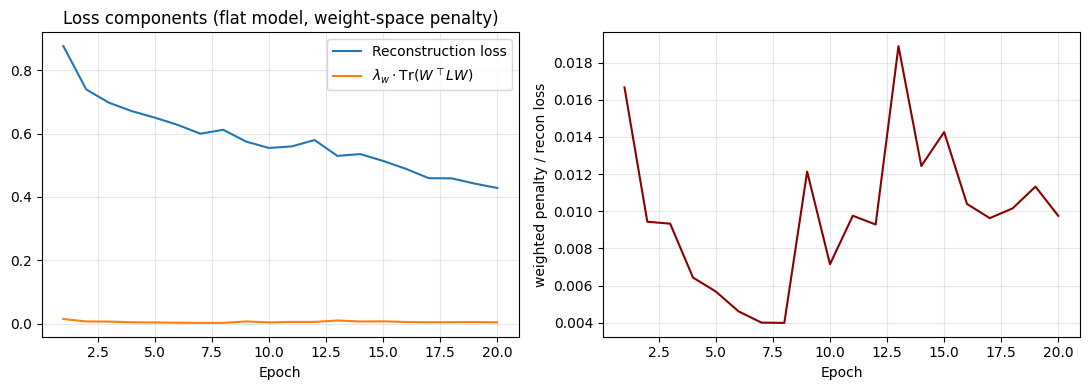

Ratio at epoch 1: 0.0167 | final epoch: 0.0098 | max: 0.0189 at epoch 13


In [ ]:

# -------------------------------------------------
# Loss-ratio plot for THIS penalty
# -------------------------------------------------
import matplotlib.pyplot as plt

h = history_runs_flatlap[0]  # seed 0's history
epochs_arr = np.array(h["epoch"])
recon_arr = np.array(h["train_recon"])
weighted_penalty_arr = LAMBDA_W * np.array(h["weight_penalty"])
ratio = weighted_penalty_arr / recon_arr

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs_arr, recon_arr, label="Reconstruction loss")
axes[0].plot(epochs_arr, weighted_penalty_arr, label=r"$\lambda_w \cdot \mathrm{Tr}(W^\top L W)$")
axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Loss components (flat model, weight-space penalty)")

axes[1].plot(epochs_arr, ratio, color="darkred")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("weighted penalty / recon loss")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Ratio at epoch 1: {ratio[0]:.4f} | final epoch: {ratio[-1]:.4f} | max: {ratio.max():.4f} at epoch {int(epochs_arr[ratio.argmax()])}")


In [ ]:
# -------------------------------------------------
# Geometry stability -- reuses the already-saved
# Z_runs_flat_weightlap.npz, no retraining needed.
# -------------------------------------------------
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr, pearsonr
from itertools import combinations

def flatten_distance_matrix(Z, metric="euclidean"):
    assert isinstance(Z, np.ndarray) and Z.ndim == 2
    return pdist(Z, metric=metric)

def geometry_stability(Z_runs, metric="euclidean"):
    assert isinstance(Z_runs, (list, tuple)) and len(Z_runs) >= 2
    n_patients = Z_runs[0].shape[0]
    for i, Z in enumerate(Z_runs):
        assert Z.shape[0] == n_patients, f"Run {i} has mismatched patient count"
    dist_vecs = [flatten_distance_matrix(Z, metric=metric) for Z in Z_runs]
    rows = []
    for (i, dv_i), (j, dv_j) in combinations(enumerate(dist_vecs), 2):
        rows.append({
            "run_a": i, "run_b": j,
            "spearman_dist_corr": spearmanr(dv_i, dv_j).correlation,
            "pearson_dist_corr": pearsonr(dv_i, dv_j)[0],
        })
    return pd.DataFrame(rows)

# Load the already-saved embeddings from the earlier run
loaded = np.load("Z_runs_flat_weightlap.npz")
Z_runs_reloaded = {int(k): loaded[k] for k in loaded.files}
Z_list = [Z_runs_reloaded[s] for s in sorted(Z_runs_reloaded.keys())]

geom_stab_flatlap_df = geometry_stability(Z_list, metric="euclidean")
print("=== Geometry stability (Flat DAE + weight-space Laplacian) ===")
print(geom_stab_flatlap_df.describe())
print(f"\nSpearman rho: mean = {geom_stab_flatlap_df['spearman_dist_corr'].mean():.4f} "
      f"+/- {geom_stab_flatlap_df['spearman_dist_corr'].std():.4f}")

=== Geometry stability (Flat DAE + weight-space Laplacian) ===
           run_a      run_b  spearman_dist_corr  pearson_dist_corr
count  10.000000  10.000000           10.000000          10.000000
mean    1.000000   3.000000            0.911010           0.895609
std     1.054093   1.054093            0.023681           0.023273
min     0.000000   1.000000            0.864772           0.844569
25%     0.000000   2.250000            0.896250           0.891685
50%     1.000000   3.000000            0.915865           0.897769
75%     1.750000   4.000000            0.925759           0.907457
max     3.000000   4.000000            0.943071           0.928568

Spearman rho: mean = 0.9110 +/- 0.0237


In [43]:

# -------------------------------------------------
# Reusable k-sweep: given already-trained per-seed embeddings, re-cluster at each
# k in {2..8} and compute restart ARI/NMI -- NO retraining needed, since training
# doesn't depend on k at all (k only enters at the k-means step after Z is extracted).
# -------------------------------------------------
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def restart_ari_vs_k(Z_runs_dict, k_values=range(2, 9), label=""):
    seeds = sorted(Z_runs_dict.keys())
    results = []
    for k in k_values:
        labels_by_seed = {s: KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(Z_runs_dict[s])
                           for s in seeds}
        aris, nmis = [], []
        for i in range(len(seeds)):
            for j in range(i + 1, len(seeds)):
                aris.append(adjusted_rand_score(labels_by_seed[seeds[i]], labels_by_seed[seeds[j]]))
                nmis.append(normalized_mutual_info_score(labels_by_seed[seeds[i]], labels_by_seed[seeds[j]]))
        results.append({"k": k, "mean_ARI": np.mean(aris), "std_ARI": np.std(aris),
                         "mean_NMI": np.mean(nmis), "std_NMI": np.std(nmis)})
    df = pd.DataFrame(results)
    print(f"\n=== Restart ARI/NMI vs. k -- {label} ===")
    print(df.to_string(index=False))
    return df


In [44]:

# -------------------------------------------------
# Run the k-sweep on this notebook's own 5-seed embeddings (already saved above, no retraining)
# -------------------------------------------------
k_sweep_flatlap_df = restart_ari_vs_k(Z_runs_flatlap, label="Flat DAE + weight-space Laplacian")



=== Restart ARI/NMI vs. k -- Flat DAE + weight-space Laplacian ===
 k  mean_ARI  std_ARI  mean_NMI  std_NMI
 2  0.594141 0.468814  0.570838 0.461218
 3  0.868908 0.056569  0.848172 0.054110
 4  0.767794 0.088403  0.758978 0.066954
 5  0.688315 0.084679  0.713237 0.061039
 6  0.658579 0.069691  0.695277 0.069178
 7  0.708602 0.059383  0.729120 0.049844
 8  0.700813 0.082140  0.739632 0.038953
